# Alert bets: closing line value vs. P&L

Every SMS alert the monitor sends is treated as a bet at the first price it was texted
at, the entry a person acting on the first text would have got
(`shadow_clv.shadow_alerts_as_bets`). No money is at risk; the point is to find out
whether the alerts have edge before any is.

**P&L (§3) uses the stake each text suggested:** 0.375× Kelly on a fixed $100 bankroll,
capped at $2. Every per-bet statistic elsewhere is per $1, so a $0.20 longshot and a $2
prop count equally when the question is whether there's edge.

Four questions:

1. **Do the alerts beat the close?** (§2)
2. **How much of the P&L is luck?** (§3)
3. **Does closing value predict realized P&L on these bets?** (§4–5)
4. **How many bets would it take to know?** (§8)

### Yardsticks

| Metric | Definition | Reads |
|---|---|---|
| **Closing EV** (primary) | `p_close × d − 1` | expected profit per $1 if Pinnacle's devigged close is the true probability. Uses the price actually paid. Same yardstick as the pre-registrations (§3) |
| Probability CLV | `p_close − p_entry` | did Pinnacle's fair line move toward our side after the alert? Ignores the price paid |
| Price CLV | `d_entry / d_close − 1` | did our own book's price get worse after we "bet"? |
| Realized ROI | profit per $1 | the outcome, which is mostly noise over a few hundred bets |

`p` is Pinnacle's devigged (Shin) fair probability, `d` the decimal price. Spread and
total closes are translated onto the bet's line via the residual sigma
(`clv/line_adjust.py`).

**Inference.** Bets from one game share its news and its outcome, and one contract
alerted at four books is one result, not four. Every CI here is a **game-clustered
bootstrap** (`clv.metrics.clustered_bootstrap`): it resamples games, not bets. Quotes with
entry EV above 15% are excluded as bad quotes, as in the pre-registration.

**Where the close isn't a valid yardstick.** The 2023–24 calibration gates
(`docs/analysis/train_results_2026-10-04.md` §1–2) found two places where Pinnacle's close
is miscalibrated: **rushing-yards props** (overs came in 3.1pp under its price) and
**moneyline short underdogs**, decimal 2.0–3.0 (over-rated by about 6pp). Closing EV
there overstates value, so those bets are left out of every closing-EV number below,
exactly as the pre-registration does.

**What's sealed.** This notebook reads through the same door as `make clv-report`, so
it inherits `src/clv/seals.py`. Weeks 5–9 player props stay hidden until 2026-11-10
(H1/H1b holdout) and Weeks 10–14 `moneyline_ev` until 2026-12-15 (H5). Re-run with
`REFRESH = True` after those dates and they're included automatically.

**What this can't see.** An alert is not a fill: some prices were gone before a
person could act. So closing EV here is an upper bound on what was capturable.
`make decision-report` measures survival separately.

In [1]:
import os
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from scipy.stats import binomtest

ROOT = Path("..").resolve()
assert (ROOT / "pyproject.toml").exists(), f"unexpected repo root: {ROOT}"
# Some library code (e.g. middle_scan's residual-sigma cache, used to translate spread
# and total closes onto the bet's line) reads data/ relative to the working directory.
os.chdir(ROOT)

from src.backtest.clv_portfolio import bets_to_frame
from src.backtest.validation import benjamini_hochberg
from src.clv.metrics import clustered_bootstrap
from src.clv.prereg_score import BAD_QUOTE_EV, GATE_FAILED_STATS, MIN_GAMES, N_BOOT, SEED, week_of
from src.clv.seals import seal_reason, withheld
from src.clv.shadow_clv import shadow_clv
from src.model.evaluate import power_analysis
from src.signal.shadow_log import load
from src.signal.sizing import apply_bankroll_caps, fractional_kelly
from src.store.bet_log import load_settlement_inputs, settle_bets
from src.store.pit_store import PointInTimeStore, kickoffs_from_store

SHADOW_LOG = ROOT / "data" / "shadow_log.jsonl"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

# Colour follows the strategy everywhere in this notebook, in a fixed order.
STRATEGIES = ["moneyline_ev", "prop_ev", "prop_arb", "steam", "middle"]
COLORS = dict(zip(STRATEGIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
INK, MUTED, BAND, GRID = "#0b0b0b", "#52514e", "#e6e6e3", "#ececea"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#9a9993",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False, "text.parse_math": False,
})

## 1. The sample

Pricing every alert against the point-in-time store takes about 6–7 minutes, so the
result is cached for the day under `data/cache/` (gitignored). Set `REFRESH = True` to
recompute, for example after re-pulling results with `make data`.

In [2]:
REFRESH = False
CACHE = ROOT / "data" / "cache" / f"alert_bets_{date.today():%Y%m%d}.pkl"

if CACHE.exists() and not REFRESH:
    bets = pd.read_pickle(CACHE)
else:
    store = PointInTimeStore(root=ROOT / "data" / "snapshots")
    priced = shadow_clv(store, path=SHADOW_LOG)
    schedule, player_stats = load_settlement_inputs(ROOT / "data" / "static")
    # settle_bets returns kickoff order, which is what the cumulative plots need.
    graded = settle_bets(priced, schedule, kickoffs_from_store(store), player_stats=player_stats)
    bets = bets_to_frame(graded)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    bets.to_pickle(CACHE)

bets = bets.reset_index(drop=True)
bets["settle_order"] = np.arange(len(bets))
bets["week"] = bets["event_id"].map(week_of)
bets["close_ev"] = bets["close_prob_fair"] * bets["price_decimal"] - 1
bets["entry_ev"] = bets["entry_prob_fair"] * bets["price_decimal"] - 1
# close_ev = entry_ev + market_move: the edge the scanner saw, plus what the market did after.
bets["market_move"] = (bets["close_prob_fair"] - bets["entry_prob_fair"]) * bets["price_decimal"]
bets["profit"] = bets["payout"]          # $1 notional stake, so payout is profit per $1
bets["measurable"] = bets["close_ev"].notna()
bets["settled"] = bets["profit"].notna()
bets["bad_quote"] = bets["entry_ev"] > BAD_QUOTE_EV
# Calibration gates: the close is measured miscalibrated here, so closing EV is not valid.
bets["gate_fail"] = bets["prop_stat"].isin(GATE_FAILED_STATS) | (
    (bets["market"] == "moneyline") & bets["price_decimal"].between(2.0, 3.0, inclusive="left"))

core = bets[bets["measurable"] & ~bets["bad_quote"] & ~bets["gate_fail"]]   # the analysis set
settled_core = core[core["settled"]]

alerts = [o for o in load(SHADOW_LOG) if o.is_alert]
sealed = pd.Series([seal_reason(o.strategy, o.event_id, o.market) for o in alerts]).value_counts()
print(f"alert rows in the shadow log: {len(alerts):,}   unique alert bets (unsealed): {len(bets):,}")
for reason, n in sealed.items():
    print(f"  sealed right now: {n:,} alert rows  ({reason})")
print(f"cache: {CACHE.name}")

def weeks(w):
    return ",".join(str(x) for x in sorted(w.unique()))

(bets.groupby("strategy")
     .agg(bets=("event_id", "size"), games=("event_id", "nunique"), weeks=("week", weeks),
          with_close=("measurable", "sum"), bad_quotes=("bad_quote", "sum"), gate_failed=("gate_fail", "sum"),
          analysed=("strategy", lambda s: int(core.index.isin(s.index).sum())), settled=("settled", "sum"))
     .reindex(STRATEGIES))

alert rows in the shadow log: 917   unique alert bets (unsealed): 529
  sealed right now: 241 alert rows  (H1/H1b: Weeks 5-9 player props)
cache: alert_bets_20261103.pkl


,bets,games,weeks,with_close,bad_quotes,gate_failed,analysed,settled
strategy,,,,,,,,
moneyline_ev,180,71,"1,2,3,4,5,6,7,8,9",156,4,33,121,156
prop_ev,143,51,"1,2,3,4",143,2,4,137,140
prop_arb,76,29,"1,2,3,4",68,1,2,65,72
steam,112,48,"1,2,3,4,5,6,7,8,9",100,7,0,93,100
middle,18,5,"3,5,7,8",18,3,0,15,18


### Stakes: what each text told you to bet

| Strategy | Stake | Source |
|---|---|---|
| moneyline EV | `Suggested stake $X`: 0.375× Kelly of $100 at Pinnacle's fair probability, $0.10–$2 | texted |
| steam | `Suggested stake $X`: the same rule at the Normal-model win probability | texted |
| middles | $2 a leg (`$4.00 risked`) | texted |
| prop EV | no stake in the text; the same Kelly rule at the texted Pinnacle fair probability | **assumed** |
| prop arb | no stake in the text; $2 per arb, split so either leg winning pays the same | **assumed** |

The shadow log doesn't store the stake, but it does store each alert's texted edge (EV per
$1 at the probability the scanner used). For the Kelly strategies `p = (1 + edge) / d`
recovers that probability exactly, so the stake is rebuilt with the same `signal.sizing`
functions the texts used. The bankroll is a fixed $100 with no compounding, as in the
scanners. $2 per arb is what the monitor's exposure cap charges one.

In [3]:
KEY = ["event_id", "decision_time", "strategy", "market", "side", "line", "book", "player_name", "prop_stat"]
ARB_TOTAL, MIDDLE_LEG = 2.0, 2.0

# Same selection as shadow_alerts_as_bets (earliest leg per alert, sealed legs skipped),
# keeping the texted edge and alert key, which the bet frame doesn't carry.
seen, rows = set(), []
for o in sorted(load(SHADOW_LOG), key=lambda o: o.alerted_at):
    if not o.is_alert or o.price_american is None or withheld(o.strategy, o.event_id, market=o.market):
        continue
    if (o.alert_key, o.leg) in seen:
        continue
    seen.add((o.alert_key, o.leg))
    rows.append({"event_id": o.event_id, "decision_time": o.capture_time or o.alerted_at,
                 "strategy": o.strategy, "market": o.market.value, "side": o.side.value, "line": o.line,
                 "book": o.book, "player_name": o.player_name, "prop_stat": o.prop_stat,
                 "alert_key": o.alert_key, "leg": o.leg, "texted_edge": o.edge})
texted = pd.DataFrame(rows)

# Identical keys are identical bets (same contract, book, line and capture). Only fixed-stake
# middles repeat one, so pairing repeats by order can't change a stake.
dups = texted[texted.duplicated(KEY, keep=False)]
assert dups["strategy"].eq("middle").all(), dups["strategy"].unique()
left = bets[KEY].assign(_n=bets.groupby(KEY, dropna=False).cumcount())
right = texted.assign(_n=texted.groupby(KEY, dropna=False).cumcount())
joined = left.merge(right, on=KEY + ["_n"], how="left", validate="one_to_one")
assert joined["alert_key"].notna().all(), "every bet must map back to the alert that texted it"
joined.index = bets.index


def kelly_stake(edge: float, d: float) -> float:
    p = (1 + edge) / d          # edge = p·d − 1, so this is the probability the text was sized on
    raw = fractional_kelly(p, d) * 100
    return apply_bankroll_caps(raw) if raw > 0 else 0.0


arb_prices = (bets.assign(alert_key=joined["alert_key"]).query("strategy == 'prop_arb'")
                  .groupby("alert_key")["price_decimal"].apply(list))


def stake_for(strategy: str, edge: float, d: float, alert_key: str) -> float:
    if strategy in ("moneyline_ev", "steam", "prop_ev"):
        return kelly_stake(edge, d)
    if strategy == "middle":
        return MIDDLE_LEG
    prices = arb_prices.get(alert_key, [])
    if len(prices) == 2:        # stake ∝ 1/price, so either leg winning returns the same
        return ARB_TOTAL * (1 / d) / sum(1 / x for x in prices)
    return ARB_TOTAL / 2


bets["stake"] = [stake_for(s, e, d, k) for s, e, d, k in
                 zip(bets["strategy"], joined["texted_edge"], bets["price_decimal"], joined["alert_key"])]
# Replaces the notional $1 `stake` that bets_to_frame carries over from shadow_clv.
core = core.assign(stake=bets.loc[core.index, "stake"])
settled_core = settled_core.assign(stake=bets.loc[settled_core.index, "stake"])

SOURCE = {"moneyline_ev": "texted", "steam": "texted", "middle": "texted",
          "prop_ev": "assumed (Kelly rule)", "prop_arb": "assumed ($2 split)"}
(bets.groupby("strategy")["stake"]
     .agg(bets="size", mean="mean", min="min", median="median", max="max", total="sum")
     .round(2).reindex(STRATEGIES)
     .assign(source=lambda t: t.index.map(SOURCE)))

,bets,mean,min,median,max,total,source
strategy,,,,,,,
moneyline_ev,180,0.62,0.17,0.49,2.00,111.54,texted
prop_ev,143,1.80,1.02,1.91,2.00,256.99,assumed (Kelly rule)
prop_arb,76,1.00,0.66,1.00,1.34,76.00,assumed ($2 split)
steam,112,1.37,0.63,1.34,2.00,153.02,texted
middle,18,2.00,2.00,2.00,2.00,36.00,texted


In [4]:
def clustered(values, games) -> dict:
    """Mean with a game-clustered 95% CI, or NaN bounds when there's too little to resample."""
    v = np.asarray(values, dtype=float)
    g = np.asarray(games, dtype=object)
    if v.size < 2 or len(set(g)) < 2:
        return {"n": int(v.size), "n_clusters": len(set(g)), "mean": float(v.mean()) if v.size else np.nan,
                "ci_lo": np.nan, "ci_hi": np.nan, "p_one_sided": np.nan}
    return clustered_bootstrap(v, g, n_resamples=N_BOOT, random_state=SEED)


def clustered_slope(x, y, games) -> dict:
    """OLS slope of y on x, with a CI that resamples whole games.

    Same scheme as `clustered_bootstrap`: each resample draws games with replacement
    and rebuilds the regression from per-game sums, so a game's bets move together.
    """
    df = pd.DataFrame({"x": np.asarray(x, float), "y": np.asarray(y, float), "g": np.asarray(games, object)})
    per = (df.assign(one=1.0, xx=df.x ** 2, xy=df.x * df.y)
             .groupby("g")[["one", "x", "y", "xx", "xy"]].sum().to_numpy())

    def slope(s):
        n, sx, sy, sxx, sxy = np.moveaxis(s, -1, 0)
        return (n * sxy - sx * sy) / (n * sxx - sx ** 2)

    g = per.shape[0]
    draws = np.random.default_rng(SEED).multinomial(g, np.full(g, 1 / g), size=N_BOOT)
    boots = slope(draws @ per)
    return {"slope": float(slope(per.sum(axis=0))), "ci_lo": float(np.nanpercentile(boots, 2.5)),
            "ci_hi": float(np.nanpercentile(boots, 97.5)), "n": len(df), "games": g}


def wilson(k: int, n: int) -> tuple[float, float]:
    if n == 0:
        return np.nan, np.nan
    ci = binomtest(k, n).proportion_ci(confidence_level=0.95, method="wilson")
    return ci.low, ci.high


def pct(v, digits=1):
    return "—" if pd.isna(v) else f"{v * 100:+.{digits}f}%"


def with_ci(mean, lo, hi, digits=1):
    return pct(mean, digits) if pd.isna(lo) else f"{pct(mean, digits)}  [{pct(lo, digits)}, {pct(hi, digits)}]"


def sign_of(lo, hi):
    if pd.isna(lo):
        return "—"
    return "above 0" if lo > 0 else "below 0" if hi < 0 else "spans 0"

## 2. Scorecard: do the alerts beat the close?

One row per strategy. **Closing EV** is the primary test (H₀: mean ≤ 0, one-sided,
game-clustered); Benjamini–Hochberg runs across the strategies. This family is
exploratory, not pre-registered, so a rejection here is a lead, not a result.

- Realized ROI here is per $1: every bet counts the same. §3 weights by the texted stakes.
- `p(EV>0)` is one-sided; the CI is two-sided 95%. So a pooled p of 0.03 can sit next to
  a CI that just touches zero. That's not a contradiction.
- *Beat rate* excludes exact ties and is **not** clustered, so its Wilson interval is
  too narrow. It's descriptive only.
- `prop_arb` is market-neutral by construction: its two legs' probability CLVs cancel,
  so a beat rate means nothing for it. Its closing EV is still meaningful, as the
  expected arb margin under the close. Its realized ROI is not a locked-in margin: a flat
  $1 on each leg isn't the hedged stake split, so which side wins still moves the P&L.
- Fewer than 15 games and the clustered CI is untrustworthy (`MIN_GAMES`, from the
  pre-registration). Those rows are flagged.

In [5]:
def score_row(name, d, directional=True):
    ev = clustered(d["close_ev"], d["event_id"])
    st = d[d["settled"]]
    roi = clustered(st["profit"], st["event_id"])
    nz = d["clv_probability"][d["clv_probability"].abs() > 1e-12]
    k = int((nz > 0).sum())
    lo, hi = wilson(k, len(nz))
    return {
        "strategy": name, "bets": len(d), "games": d["event_id"].nunique(),
        "close_ev": ev["mean"], "close_ev_lo": ev["ci_lo"], "close_ev_hi": ev["ci_hi"],
        "p_ev_gt_0": ev["p_one_sided"],
        "prob_clv": d["clv_probability"].mean(),
        "beat": k / len(nz) if directional and len(nz) else np.nan,
        "beat_lo": lo if directional else np.nan, "beat_hi": hi if directional else np.nan,
        "price_clv": d["clv_price"].mean(),
        "settled": len(st), "roi": roi["mean"], "roi_lo": roi["ci_lo"], "roi_hi": roi["ci_hi"],
    }

score = pd.DataFrame([score_row(s, core[core["strategy"] == s], directional=s != "prop_arb") for s in STRATEGIES])
testable = score["p_ev_gt_0"].notna()
score["bh_reject"] = False
score.loc[testable, "bh_reject"] = benjamini_hochberg(score.loc[testable, "p_ev_gt_0"].to_numpy(), q=0.05)
pooled = score_row("ALL", core, directional=True)
# The pooled beat rate leaves out prop_arb, whose legs cancel by construction.
no_arb = core[core["strategy"] != "prop_arb"]["clv_probability"]
nz = no_arb[no_arb.abs() > 1e-12]
pooled.update(beat=(nz > 0).mean(), beat_lo=wilson(int((nz > 0).sum()), len(nz))[0],
              beat_hi=wilson(int((nz > 0).sum()), len(nz))[1])
score_all = pd.concat([score, pd.DataFrame([pooled])], ignore_index=True)

gated = bets[bets["measurable"] & ~bets["bad_quote"] & bets["gate_fail"]]
print(f"left out by the calibration gates: {len(gated)} bets "
      f"(closing EV {gated['close_ev'].mean():+.1%} as measured, not a valid yardstick there)")

pd.DataFrame({
    "strategy": score_all["strategy"],
    "bets / games": [f"{b} / {g}" + ("  (few games)" if g < MIN_GAMES else "") for b, g in zip(score_all["bets"], score_all["games"])],
    "closing EV [95% CI]": [with_ci(m, lo, hi) for m, lo, hi in zip(score_all["close_ev"], score_all["close_ev_lo"], score_all["close_ev_hi"])],
    "CI": [sign_of(lo, hi) for lo, hi in zip(score_all["close_ev_lo"], score_all["close_ev_hi"])],
    "p(EV>0)": score_all["p_ev_gt_0"].map(lambda p: "—" if pd.isna(p) else f"{p:.3f}"),
    "BH": score_all["bh_reject"].map(lambda r: "reject" if r is True else ("—" if pd.isna(r) else "")),
    "prob CLV": score_all["prob_clv"].map(lambda v: f"{v * 100:+.2f}pp"),
    "beat rate [naive CI]": [("—" if pd.isna(b) else f"{b:.0%}  [{lo:.0%}, {hi:.0%}]") for b, lo, hi in zip(score_all["beat"], score_all["beat_lo"], score_all["beat_hi"])],
    "price CLV": score_all["price_clv"].map(lambda v: pct(v, 2)),
    "settled": score_all["settled"],
    "realized ROI [95% CI]": [with_ci(m, lo, hi) for m, lo, hi in zip(score_all["roi"], score_all["roi_lo"], score_all["roi_hi"])],
}).set_index("strategy")

left out by the calibration gates: 38 bets (closing EV +2.4% as measured, not a valid yardstick there)


,bets / games,closing EV [95% CI],CI,p(EV>0),BH,prob CLV,beat rate [naive CI],price CLV,settled,realized ROI [95% CI]
strategy,,,,,,,,,,
moneyline_ev,121 / 47,"+1.9% [-1.2%, +4.8%]",spans 0,0.106,,-0.54pp,"36% [28%, 45%]",+4.63%,121,"+27.0% [-33.0%, +90.9%]"
prop_ev,137 / 50,"+2.9% [+1.6%, +4.1%]",above 0,0.000,reject,-1.06pp,"27% [20%, 35%]",+5.24%,134,"-2.1% [-24.2%, +20.9%]"
prop_arb,65 / 26,"+1.2% [+0.8%, +1.6%]",above 0,0.000,reject,+0.04pp,—,+5.43%,63,"+6.7% [+1.5%, +12.2%]"
steam,93 / 44,"-3.4% [-5.8%, -0.9%]",below 0,0.998,,-1.84pp,"37% [27%, 47%]",+0.24%,93,"-13.9% [-40.8%, +13.7%]"
middle,15 / 5 (few games),"+3.2% [-0.9%, +6.7%]",spans 0,0.060,,+0.81pp,"67% [42%, 85%]",-0.43%,15,"-11.6% [-48.7%, +10.9%]"
ALL,431 / 100,"+1.0% [-0.2%, +2.1%]",spans 0,0.048,—,-0.86pp,"34% [30%, 39%]",+3.88%,426,"+4.6% [-14.3%, +24.2%]"


## 3. P&L against what the close expected: how much is luck?

Every bet here carries its texted stake `s`. If Pinnacle's close is the true probability
`p`, a bet at decimal price `d` has expected profit `s·(p·d − 1)`, its stake times its
closing EV, and variance `s²·p(1 − p)·d²`. Summing over bets gives the P&L the close
*expects* and how far luck alone could carry it. Each panel plots realized P&L against
that expectation, in kickoff order, with the 95% band around it.

- Realized P&L **inside** the band: the result is consistent with zero skill beyond
  what the close already credits.
- **Above** the band: something the close didn't price, or luck rarer than 1 in 40.

The band assumes independent bets. Same-game bets are correlated, so the true band is
wider; the table's clustered CI on total luck is the honest version. The last two columns
repeat the totals at a flat $1 per bet. Same alerts, different sizing.

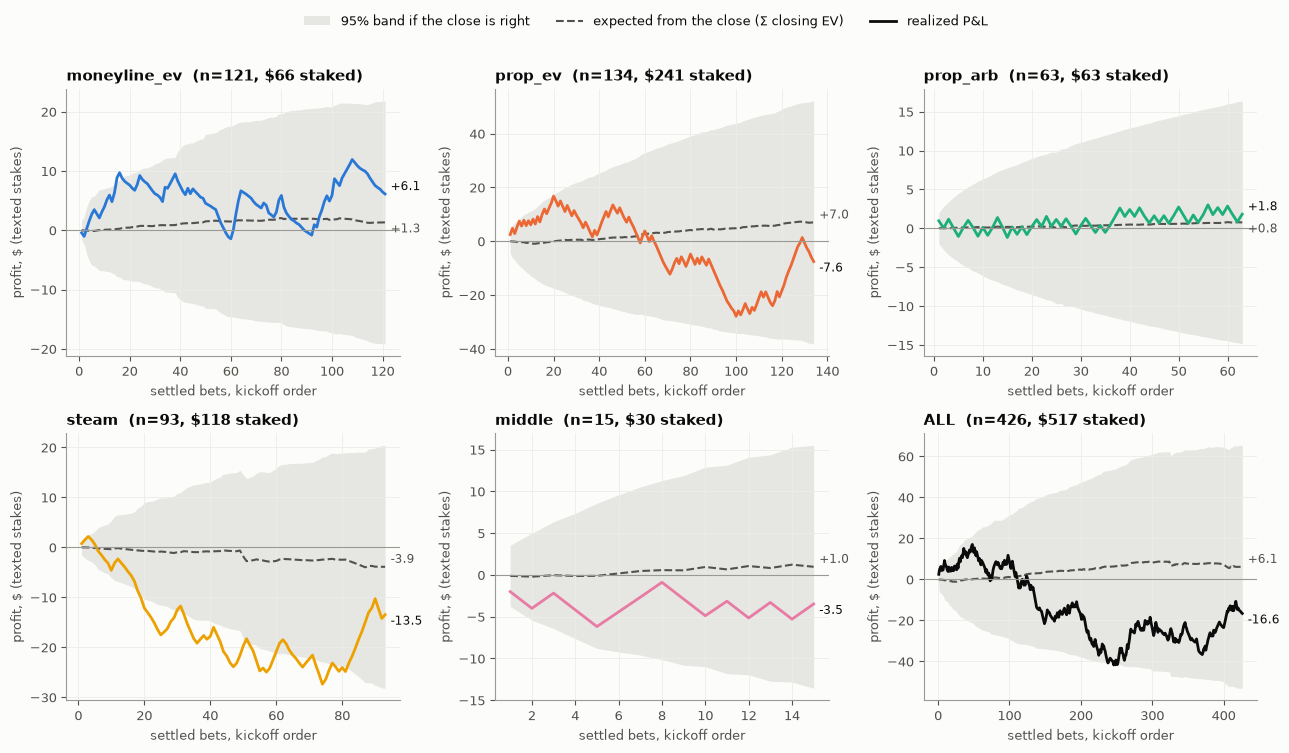

,settled,staked $,realized $,ROI,expected $,closing EV per $,luck $ [clustered 95% CI],z (independent),flat $1: realized,flat $1: expected
strategy,,,,,,,,,,
moneyline_ev,121,65.55,6.12,+9.3%,1.32,+2.01%,"+4.80 [-28.17, +40.09]",0.46,32.64,2.31
prop_ev,134,240.55,-7.56,-3.1%,6.99,+2.91%,"-14.55 [-67.12, +38.93]",-0.63,-2.82,3.78
prop_arb,63,63.06,1.82,+2.9%,0.76,+1.20%,"+1.06 [-0.00, +3.29]",0.13,4.24,0.79
steam,93,118.26,-13.48,-11.4%,-3.89,-3.29%,"-9.59 [-46.89, +28.87]",-0.77,-12.88,-3.21
middle,15,30.00,-3.48,-11.6%,0.97,+3.24%,"-4.45 [-14.66, +1.29]",-0.60,-1.74,0.49
ALL,426,517.42,-16.59,-3.2%,6.14,+1.19%,"-22.73 [-94.95, +48.36]",-0.75,19.44,4.16


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.4))
luck_rows = []
for ax, name in zip(axes.flat, STRATEGIES + ["ALL"]):
    d = settled_core if name == "ALL" else settled_core[settled_core["strategy"] == name]
    d = d.sort_values("settle_order")
    color = COLORS.get(name, INK)
    if len(d) == 0:
        ax.set_title(f"{name} — no settled bets")
        continue
    p, dec, w = d["close_prob_fair"], d["price_decimal"], d["stake"]
    var = w ** 2 * p * (1 - p) * dec ** 2
    x = np.arange(1, len(d) + 1)
    expected, sd, realized = (w * d["close_ev"]).cumsum(), np.sqrt(var.cumsum()), (w * d["profit"]).cumsum()

    ax.fill_between(x, expected - 1.96 * sd, expected + 1.96 * sd, color=BAND, lw=0, label="95% band if the close is right")
    ax.plot(x, expected, color=MUTED, lw=1.5, ls="--", label="expected from the close (Σ closing EV)")
    ax.plot(x, realized, color=color, lw=2, label="realized P&L")
    ax.axhline(0, color="#9a9993", lw=0.8)
    R, E, V = realized.iloc[-1], expected.iloc[-1], var.sum()
    # Nudge the two end labels apart so they can't overprint when R and E are close.
    up = 5 if R >= E else -5
    ax.annotate(f"{R:+.1f}", (x[-1], R), xytext=(4, up), textcoords="offset points", color=INK, fontsize=8.5, va="center")
    ax.annotate(f"{E:+.1f}", (x[-1], E), xytext=(4, -up), textcoords="offset points", color=MUTED, fontsize=8.5, va="center")
    ax.set_title(f"{name}  (n={len(d)}, ${w.sum():.0f} staked)")
    ax.set_xlabel("settled bets, kickoff order")
    ax.set_ylabel("profit, $ (texted stakes)")

    n = len(d)
    luck = clustered(w * (d["profit"] - d["close_ev"]), d["event_id"])   # per-bet luck in $; total = n × mean
    luck_rows.append({"strategy": name, "settled": n, "staked $": round(w.sum(), 2),
                      "realized $": round(R, 2), "ROI": pct(R / w.sum()),
                      "expected $": round(E, 2), "closing EV per $": pct(E / w.sum(), 2),
                      "luck $ [clustered 95% CI]": f"{R - E:+.2f}  [{luck['ci_lo'] * n:+.2f}, {luck['ci_hi'] * n:+.2f}]",
                      "z (independent)": round((R - E) / np.sqrt(V), 2),
                      "flat $1: realized": round(d["profit"].sum(), 2), "flat $1: expected": round(d["close_ev"].sum(), 2)})

handles, labels = axes.flat[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

pd.DataFrame(luck_rows).set_index("strategy")

## 4. Does closing value predict P&L on *these* bets?

The CLV thesis says closing value is a leading indicator of profit. That can be checked
directly on our own alerts.

- **Left:** bets binned by closing EV, against realized profit per $1 in each bin. If the
  close is an unbiased forecast, the points lie on the dashed `y = x` line. The fitted
  slope (game-clustered CI) is 1 for a perfect forecast and 0 for no relationship.
- **Right:** the same against probability CLV, the simpler "did the line move our way"
  measure. A monotone rise means the close knew more than the entry price did.

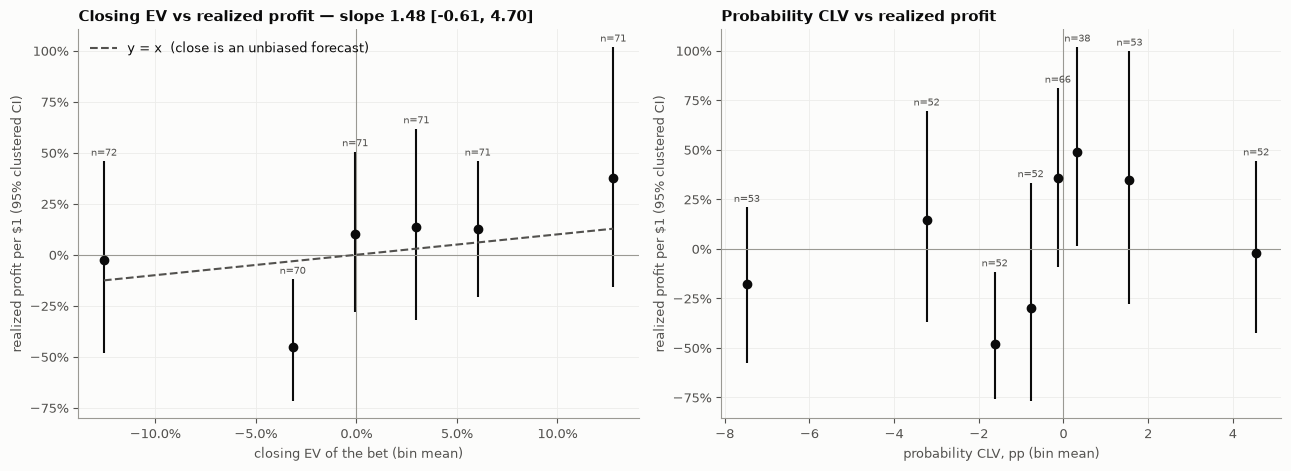

slope of profit on closing EV: 1.48  95% CI [-0.61, 4.70]  (n=426, 100 games)


In [7]:
sc = settled_core.copy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

def binned(ax, col, q, scale, xlabel):
    sc["bin"] = pd.qcut(sc[col], q, duplicates="drop")
    rows = []
    for _, d in sc.groupby("bin", observed=True):
        r = clustered(d["profit"], d["event_id"])
        rows.append((d[col].mean() * scale, r["mean"], r["ci_lo"], r["ci_hi"], len(d)))
    b = pd.DataFrame(rows, columns=["x", "y", "lo", "hi", "n"])
    ax.errorbar(b["x"], b["y"], yerr=[b["y"] - b["lo"], b["hi"] - b["y"]], fmt="o", color=INK,
                ms=6, lw=1.5, capsize=0)
    for _, r in b.iterrows():
        ax.annotate(f"n={int(r.n)}", (r.x, r.hi), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=7.5, color=MUTED)
    ax.axhline(0, color="#9a9993", lw=0.8)
    ax.axvline(0, color="#9a9993", lw=0.8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("realized profit per $1 (95% clustered CI)")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    return b

b1 = binned(ax1, "close_ev", 6, 1.0, "closing EV of the bet (bin mean)")
lims = np.array([b1["x"].min(), b1["x"].max()])
ax1.plot(lims, lims, ls="--", color=MUTED, lw=1.5, label="y = x  (close is an unbiased forecast)")
ax1.legend(loc="upper left")
ax1.xaxis.set_major_formatter(PercentFormatter(1.0))
fit = clustered_slope(sc["close_ev"], sc["profit"], sc["event_id"])
ax1.set_title(f"Closing EV vs realized profit — slope {fit['slope']:.2f} [{fit['ci_lo']:.2f}, {fit['ci_hi']:.2f}]")

binned(ax2, "clv_probability", 8, 100, "probability CLV, pp (bin mean)")
ax2.set_title("Probability CLV vs realized profit")
fig.tight_layout()
plt.show()

print(f"slope of profit on closing EV: {fit['slope']:.2f}  95% CI [{fit['ci_lo']:.2f}, {fit['ci_hi']:.2f}]"
      f"  (n={fit['n']}, {fit['games']} games)")

## 5. Is the close calibrated on the bets we picked?

Everything above assumes Pinnacle's close is a good probability for our bets. Alerts are
a selected sample (prices where books disagree), so that's worth testing rather than
assuming. The 2023–24 history already found one place it fails: the moneyline close
over-rated short underdogs (fair .33–.50) by about 6pp.

Reliability: bets binned by forecast probability, against the realized win rate
(pushes excluded). Points on the diagonal are calibrated. The *entry* fair probability
is shown for comparison; the Brier difference says how much information the market
added between the alert and kickoff.

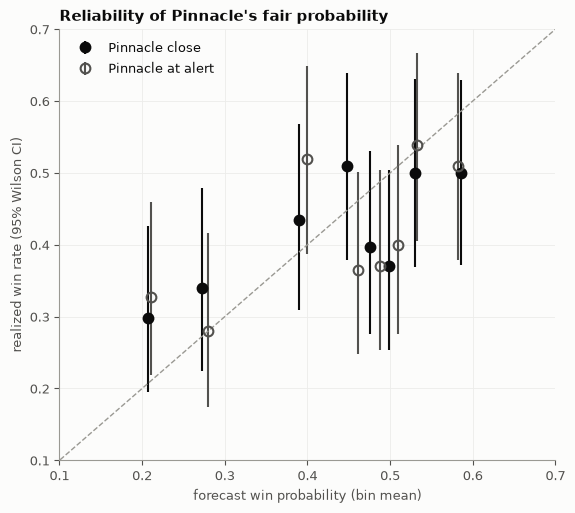

Brier at alert 0.2440  ->  at close 0.2445   (improvement -0.0005, 95% clustered CI [-0.0071, +0.0056], n=418)


In [8]:
rel = settled_core[settled_core["outcome"].isin(["win", "loss"])].copy()
rel["y"] = (rel["outcome"] == "win").astype(float)

fig, ax = plt.subplots(figsize=(6.4, 5.6))
for col, label, style in [("close_prob_fair", "Pinnacle close", dict(color=INK, mfc=INK)),
                          ("entry_prob_fair", "Pinnacle at alert", dict(color=MUTED, mfc="none"))]:
    d = rel[rel[col].notna()].copy()
    d["bin"] = pd.qcut(d[col], 8, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(p=(col, "mean"), k=("y", "sum"), n=("y", "size"))
    ci = np.array([wilson(int(k), int(n)) for k, n in zip(g["k"], g["n"])])
    rate = g["k"] / g["n"]
    ax.errorbar(g["p"], rate, yerr=[rate - ci[:, 0], ci[:, 1] - rate], fmt="o", ms=7, lw=1.5,
                mew=1.5, capsize=0, label=label, **style)
ax.plot([0, 1], [0, 1], ls="--", color="#9a9993", lw=1)
ax.set_xlim(0.1, 0.7)
ax.set_ylim(0.1, 0.7)
ax.set_xlabel("forecast win probability (bin mean)")
ax.set_ylabel("realized win rate (95% Wilson CI)")
ax.set_title("Reliability of Pinnacle's fair probability")
ax.legend(loc="upper left")
plt.show()

both = rel[rel["entry_prob_fair"].notna()]
brier_close = (both["close_prob_fair"] - both["y"]) ** 2
brier_entry = (both["entry_prob_fair"] - both["y"]) ** 2
gain = clustered(brier_entry - brier_close, both["event_id"])
print(f"Brier at alert {brier_entry.mean():.4f}  ->  at close {brier_close.mean():.4f}   "
      f"(improvement {gain['mean']:+.4f}, 95% clustered CI [{gain['ci_lo']:+.4f}, {gain['ci_hi']:+.4f}], n={len(both)})")

## 6. Where the closing EV comes from

Closing EV splits exactly into two parts:

`closing EV = entry EV + market move`, where entry EV `= p_entry·d − 1` is the edge the
scanner saw against Pinnacle when it fired, and market move `= (p_close − p_entry)·d` is
what happened to Pinnacle's line afterwards.

Each arrow runs from the edge at the alert to the closing EV. A long leftward arrow means
the market reliably moves against the alerts: the edge was there against Pinnacle's
price *at that moment*, but Pinnacle's price itself was stale.

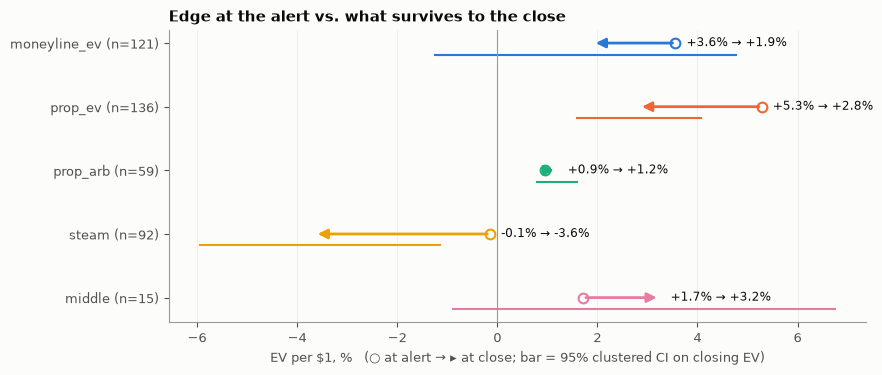

,bets,entry EV [CI],market move [CI],closing EV [CI]
moneyline_ev,121,"+3.6% [+2.8%, +4.2%]","-1.6% [-4.9%, +1.4%]","+1.9% [-1.2%, +4.8%]"
prop_ev,136,"+5.3% [+4.7%, +5.8%]","-2.4% [-4.0%, -0.8%]","+2.8% [+1.6%, +4.1%]"
prop_arb,59,"+0.9% [+0.6%, +1.3%]","+0.2% [-0.1%, +0.6%]","+1.2% [+0.8%, +1.6%]"
steam,92,"-0.1% [-1.1%, +0.7%]","-3.5% [-6.2%, -0.7%]","-3.6% [-5.9%, -1.1%]"
middle,15,"+1.7% [-5.0%, +5.7%]","+1.5% [+0.1%, +4.1%]","+3.2% [-0.9%, +6.7%]"


In [9]:
dec = core[core["entry_ev"].notna()]
rows = []
for s in STRATEGIES:
    d = dec[dec["strategy"] == s]
    e, m, c = (clustered(d[k], d["event_id"]) for k in ("entry_ev", "market_move", "close_ev"))
    rows.append({"strategy": s, "bets": len(d), "entry": e, "move": m, "close": c})

fig, ax = plt.subplots(figsize=(9, 3.8))
for i, r in enumerate(rows[::-1]):
    s, e, c = r["strategy"], r["entry"]["mean"], r["close"]["mean"]
    ax.annotate("", xy=(c * 100, i), xytext=(e * 100, i),
                arrowprops=dict(arrowstyle="-|>", color=COLORS[s], lw=2, mutation_scale=14))
    ax.plot([r["close"]["ci_lo"] * 100, r["close"]["ci_hi"] * 100], [i - 0.18, i - 0.18], color=COLORS[s], lw=1.5)
    ax.plot(e * 100, i, "o", mfc="none", mec=COLORS[s], ms=7, mew=1.5)
    ax.annotate(f"{e * 100:+.1f}% → {c * 100:+.1f}%", (max(e, c) * 100, i), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=INK)
ax.axvline(0, color="#9a9993", lw=0.8)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{r['strategy']} (n={r['bets']})" for r in rows[::-1]])
ax.set_xlabel("EV per $1, %   (○ at alert → ▸ at close; bar = 95% clustered CI on closing EV)")
ax.set_title("Edge at the alert vs. what survives to the close")
ax.grid(axis="y", visible=False)
plt.show()

pd.DataFrame({
    "bets": [r["bets"] for r in rows],
    "entry EV [CI]": [with_ci(r["entry"]["mean"], r["entry"]["ci_lo"], r["entry"]["ci_hi"]) for r in rows],
    "market move [CI]": [with_ci(r["move"]["mean"], r["move"]["ci_lo"], r["move"]["ci_hi"]) for r in rows],
    "closing EV [CI]": [with_ci(r["close"]["mean"], r["close"]["ci_lo"], r["close"]["ci_hi"]) for r in rows],
}, index=[r["strategy"] for r in rows])

## 7. Over time, and by segment

Weekly mean closing EV per strategy (weeks with at least 5 bets), then two exploratory
cuts: price band and book. The segment tables have **no p-values on purpose**. Slicing
the same few hundred bets many ways will turn up an "edge" somewhere by chance, so a
segment that looks good here is a hypothesis for a future holdout, not a finding.

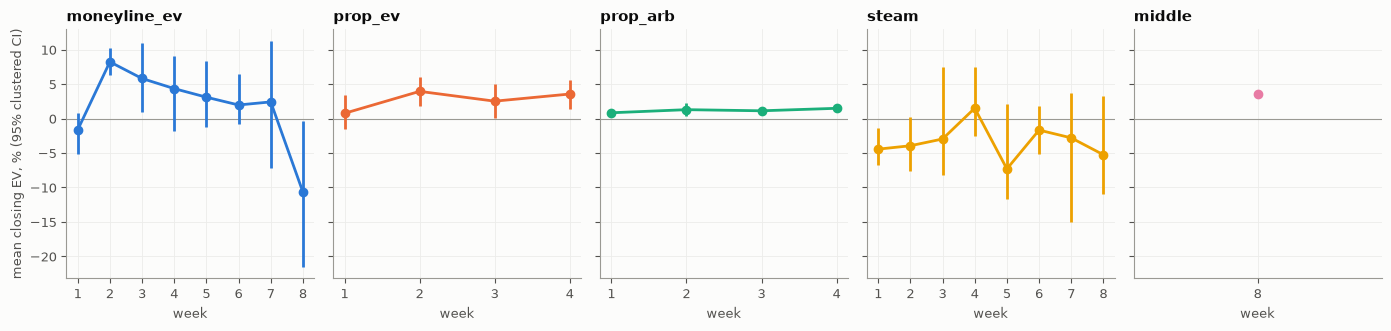

In [10]:
fig, axes = plt.subplots(1, len(STRATEGIES), figsize=(14, 3.4), sharey=True)
for ax, s in zip(axes, STRATEGIES):
    d = core[core["strategy"] == s]
    pts = []
    for w, dw in d.groupby("week"):
        if len(dw) >= 5:
            r = clustered(dw["close_ev"], dw["event_id"])
            pts.append((w, r["mean"] * 100, r["ci_lo"] * 100, r["ci_hi"] * 100, len(dw)))
    ax.axhline(0, color="#9a9993", lw=0.8)
    if pts:
        p = pd.DataFrame(pts, columns=["w", "m", "lo", "hi", "n"])
        yerr = [(p["m"] - p["lo"]).fillna(0), (p["hi"] - p["m"]).fillna(0)]
        ax.errorbar(p["w"], p["m"], yerr=yerr, fmt="o-", color=COLORS[s], lw=2, ms=6, capsize=0)
        ax.set_xticks(p["w"])
    ax.set_title(s)
    ax.set_xlabel("week")
axes[0].set_ylabel("mean closing EV, % (95% clustered CI)")
fig.tight_layout()
plt.show()

In [11]:
def segment(frame, by):
    out = []
    for key, d in frame.groupby(by, observed=True):
        ev = clustered(d["close_ev"], d["event_id"])
        st = d[d["settled"]]
        out.append({by: key, "bets": len(d), "games": d["event_id"].nunique(),
                    "closing EV [95% CI]": with_ci(ev["mean"], ev["ci_lo"], ev["ci_hi"]),
                    "realized ROI": pct(st["profit"].mean()) if len(st) else "—"})
    return pd.DataFrame(out).set_index(by)

seg = core.assign(price_band=pd.cut(core["price_decimal"], [1.0, 2.0, 3.0, np.inf],
                                    labels=["favourite (<2.0)", "short dog (2.0–3.0)", "longshot (>3.0)"]))
print("price band (moneyline 2.0–3.0 is out: gate)")
display(segment(seg, "price_band"))
display(segment(core, "book"))

price band (moneyline 2.0–3.0 is out: gate)


,bets,games,closing EV [95% CI],realized ROI
price_band,,,,
favourite (<2.0),170,72,"-1.2% [-2.7%, +0.4%]",-12.9%
short dog (2.0–3.0),149,55,"+2.5% [+1.2%, +4.0%]",+2.0%
longshot (>3.0),112,42,"+2.3% [-1.1%, +5.4%]",+33.9%


,bets,games,closing EV [95% CI],realized ROI
book,,,,
betmgm,109,60,"+0.4% [-1.5%, +2.0%]",+3.3%
betrivers,86,65,"+0.9% [-1.2%, +2.9%]",+7.2%
draftkings,112,69,"+2.4% [+0.6%, +4.0%]",+7.6%
fanduel,87,59,"+1.4% [-0.8%, +3.4%]",+4.2%
williamhill_us,37,31,"-1.9% [-7.4%, +3.1%]",-6.3%


## 8. How many bets would it take to know?

The reason CLV is the headline metric, in numbers. To detect a true edge of +1% or +2%
per bet (two-sided α = 0.05, 80% power, `model.evaluate.power_analysis`), the required
sample depends on how noisy each bet's measurement is:

- **Closing EV** varies only as much as prices and closes vary between bets.
- **Realized profit** carries the full win/lose variance of every bet.

Both are inflated by the measured **design effect** (clustered variance ÷ independent
variance), because same-game bets carry less information than their count suggests.
`moneyline_ev`'s is large because the same contract is often alerted at several books.
A season is 18 weeks.

In [12]:
def needed(values, games, effect):
    v = np.asarray(values, float)
    r = clustered(v, games)
    se_iid = v.std(ddof=1) / np.sqrt(v.size)
    se_clu = (r["ci_hi"] - r["ci_lo"]) / (2 * 1.96)
    deff = max((se_clu / se_iid) ** 2, 1.0) if np.isfinite(se_clu) else np.nan
    return int(np.ceil(power_analysis(effect, v.var(ddof=1)) * deff)) if np.isfinite(deff) else np.nan, deff

rows = []
for s in STRATEGIES:
    d = core[core["strategy"] == s]
    st = d[d["settled"]]
    if len(st) < 10:
        continue
    per_week = len(d) / d["week"].nunique()
    n_ev1, deff_ev = needed(d["close_ev"], d["event_id"], 0.01)
    n_ev2, _ = needed(d["close_ev"], d["event_id"], 0.02)
    n_roi2, deff_roi = needed(st["profit"], st["event_id"], 0.02)
    rows.append({"strategy": s, "bets now": len(d), "bets/week": round(per_week, 1),
                 "SD closing EV": round(d["close_ev"].std(), 3), "SD profit": round(st["profit"].std(), 2),
                 "design effect (EV / ROI)": f"{deff_ev:.1f} / {deff_roi:.1f}",
                 "n for +1% (closing EV)": n_ev1, "n for +2% (closing EV)": n_ev2,
                 "n for +2% (realized ROI)": n_roi2,
                 "weeks for +2%, closing EV": round(n_ev2 / per_week, 1),
                 "seasons for +2%, ROI": round(n_roi2 / per_week / 18, 1)})
pd.DataFrame(rows).set_index("strategy")

,bets now,bets/week,SD closing EV,SD profit,design effect (EV / ROI),n for +1% (closing EV),n for +2% (closing EV),n for +2% (realized ROI),"weeks for +2%, closing EV","seasons for +2%, ROI"
strategy,,,,,,,,,,
moneyline_ev,121,15.1,0.099,1.94,2.9 / 3.2,2227,558,237270,36.9,871.5
prop_ev,137,34.2,0.059,1.13,1.5 / 1.4,426,108,34764,3.2,56.4
prop_arb,65,16.2,0.061,1.08,1.0 / 1.0,296,74,23006,4.6,78.7
steam,93,11.6,0.112,0.95,1.2 / 2.0,1139,286,35286,24.6,168.6
middle,15,3.8,0.125,0.98,1.0 / 1.0,1222,306,18783,81.6,278.3


## 9. Takeaways (run of 2026-11-03)

Mainline strategies cover Weeks 1–9 (settled through Week 8); props cover Weeks 1–4 only,
because Weeks 5–9 are sealed until 2026-11-10. Gate-failed and bad-quote bets are excluded
throughout. Re-run with `REFRESH = True` and these numbers will move; the reading below
is pinned to this run.

1. **The two CLV yardsticks disagree, and the gap is the story.** Pinnacle's line moved
   *away* from almost every alert: probability CLV is negative for every directional
   strategy, with beat rates of 27–37%. Yet on closing EV, which credits the price we
   got, `prop_ev` (+2.9% [+1.6, +4.1]) and `prop_arb` (+1.2% [+0.8, +1.6]) beat
   Pinnacle's close, and both survive BH across the five strategies. §6 shows how: prop
   alerts start about 5.3% ahead of Pinnacle's fair price and give back about 2.4% as the
   market moves. Late, but still ahead. This is the same Weeks 1–4 data that shaped the
   H1 pre-registration (`train_results_2026-10-04.md` §4 recorded +3.08%), so it is not
   independent confirmation. The sealed Weeks 5–9 are.
2. **Steam is reliably negative.** It fires with no edge (−0.1% at the alert) and then
   loses 3.5% to the market: closing EV −3.4% [−5.8, −0.9]. Whatever move it chases is
   already in the price.
3. **The P&L is noise around what the close expected, and at the texted stakes it's
   negative.** Staked as texted, the bets put up $517 and lost $16.59 (−3.2%) against
   +$6.14 the close expected (+1.2% per $ staked). That's −$22.73 of luck, z = −0.75,
   inside the band. A flat $1 per alert would show **+$19.44** instead. Kelly stakes the
   moneyline longshots small (about $0.54) and the props near the $2 cap, so moneyline's
   lucky run shrinks from +$32.6 to +$6.1 while `prop_ev`'s unlucky one deepens to
   −$7.6. Same alerts, opposite-signed P&L, and neither result is evidence. That's what
   noise looks like at this sample size. `prop_ev` is the best strategy on closing EV and
   one of the worst on P&L.
4. **On these bets, closing EV's link to realized profit is consistent with theory but
   unresolved.** The slope is 1.48 [−0.61, 4.70]: compatible with an unbiased close (1.0),
   unable to rule out no relationship (0). Calibration is only roughly right: every bin
   from .47 to .59 lands at or below the diagonal (we won less often than the close
   said), and the .50 bin only just reaches it at the top of its interval. Worth
   watching once the props unseal, not a finding. Between alert and kickoff the close
   also didn't become measurably more accurate on our sample (Brier 0.2440 → 0.2445,
   CI ±0.006).
5. **Why CLV is the scoreboard, in one row each.** Detecting a +2% edge takes about
   100–560 bets on closing EV: roughly 3 weeks of `prop_ev` alerts, about 37 weeks of
   `moneyline_ev`. On realized ROI it takes 19k–240k bets, which is 56 to 870 seasons.
6. **Segments are hypotheses, not findings.** Favourites look negative, DraftKings
   alerts best and Caesars (`williamhill_us`) worst. None of those were pre-specified.

**What changes this:** the 2026-11-10 unseal adds about 240 Weeks 5–9 prop alert rows,
and H1/H1b are scored the same day with the frozen scorer
(`make prereg-score WEEKS=holdout`). `moneyline_ev` longshots are H5, sealed for
Weeks 10–14 until 2026-12-15.